In [30]:
# -*- coding: utf-8 -*-
"""
Antes/depois da instalação de semáforos — Fortaleza

Para cada semáforo escolhido:
  1. cria um RETÂNGULO (comprimento x largura configuráveis, com rotação) centrado no semáforo;
  2. seleciona os acidentes que caíram dentro do retângulo;
  3. classifica cada acidente em "antes", "no_dia" ou "depois" da data de implantação;
  4. grava UM GeoJSON com tudo junto, usando a coluna `tipo_feature`:
        - "semaforo"  (ponto do semáforo)
        - "retangulo" (polígono da área de influência)
        - "acidente"  (pontos, com codigo_semaforo, periodo e dias_desde_instalacao)

Um resumo antes/depois por semáforo é impresso no terminal (sem CSV).

Requisitos: pip install geopandas shapely pyproj
"""

import json
import pandas as pd
import geopandas as gpd
import numpy as np
from shapely.geometry import box
from shapely import affinity

# ----------------------------------------------------------------------------
# PARÂMETROS (edite aqui)
# ----------------------------------------------------------------------------
CAMINHO_SINISTROS = r"sinistros-2015-2024.geojson"
CAMINHO_SEMAFOROS = r"dadosabertos_semaforosctafor.geojson"
CAMINHO_SAIDA     = r"saida_semaforos_antes_depois.geojson"

# None = usa TODOS os semáforos que tenham dados de acidentes antes E depois da instalação.
# Ou uma lista de valores da coluna "CÓDIGO" (como texto) para restringir, ex.: ["794", "830"]
SEMAFOROS_ALVO = None

# Mínimo de dias de dados disponíveis antes e depois da instalação para o semáforo entrar
# (1 = qualquer semáforo com pelo menos algum dado dos dois lados; aumente p/ ex. 365 se quiser mais robustez)
MIN_DIAS_ANTES  = 1
MIN_DIAS_DEPOIS = 1

# Retângulo em volta do semáforo (valores = METADE da dimensão, em metros)
#   COMPRIMENTO_METADE_M: ao longo do eixo longo  (100 -> 200 m de comprimento)
#   LARGURA_METADE_M:     perpendicular ao eixo   ( 30 ->  60 m de largura)
COMPRIMENTO_METADE_M = 100
LARGURA_METADE_M     = 30

# Rotação do eixo longo, em graus, anti-horário a partir de LESTE (0 = leste-oeste, 90 = norte-sul)
#   número -> mesma rotação para todos os semáforos
#   "auto" -> alinha o eixo longo com a direção dominante dos acidentes ao redor do semáforo
#             (útil para avenidas diagonais); se houver poucos acidentes, usa ROTACAO_PADRAO_GRAUS
ROTACAO_GRAUS = "auto"
ROTACAO_PADRAO_GRAUS = 0
RAIO_AUTO_M = 100            # raio usado para estimar a direção da rua no modo "auto"
MIN_ACIDENTES_AUTO = 5

# Ajustes manuais por semáforo (sobrescrevem tudo acima). Ex.:
# OVERRIDES = {"794": {"comprimento_m": 120, "largura_m": 25, "rotacao": 45}}
OVERRIDES = {}

# Janela simétrica em anos antes/depois da instalação (None = usa todo o período disponível)
# Ex.: 2 -> compara só os 2 anos antes com os 2 anos depois (comparação mais justa)
JANELA_ANOS = None

# Se o semáforo tiver DATA_DESATIVAÇÃO, encerra o período "depois" nessa data
RESPEITAR_DESATIVACAO = True

CRS_METRICO = "EPSG:31984"   # SIRGAS 2000 / UTM 24S (metros) — usado só para montar o retângulo
CRS_SAIDA   = "EPSG:4326"    # GeoJSON de saída em lat/lon
# ----------------------------------------------------------------------------


def carregar():
    sem = gpd.read_file(CAMINHO_SEMAFOROS)
    aci = gpd.read_file(CAMINHO_SINISTROS)

    # Datas
    sem["data_implantacao"] = pd.to_datetime(sem["DATA_IMPLANTAÇÃO"], format="%d/%m/%Y", errors="coerce")
    sem["data_desativacao"] = pd.to_datetime(sem["DATA_DESATIVAÇÃO"], format="%d/%m/%Y", errors="coerce")
    aci["data_acidente"] = pd.to_datetime(
        dict(year=aci["ANO"], month=aci["MES"], day=aci["DIA"]), errors="coerce"
    )

    sem["CÓDIGO"] = sem["CÓDIGO"].astype(str)
    return sem, aci.dropna(subset=["data_acidente"]), sem


def angulo_dominante(ponto, aci_m):
    """Direção (graus, anti-horário a partir de leste) dos acidentes ao redor do ponto, via eixo principal."""
    if ROTACAO_PADRAO_GRAUS is None:
        return 0
    prox = aci_m[aci_m.geometry.distance(ponto) <= RAIO_AUTO_M]
    if len(prox) < MIN_ACIDENTES_AUTO:
        return ROTACAO_PADRAO_GRAUS
    xy = np.column_stack([prox.geometry.x, prox.geometry.y])
    vals, vecs = np.linalg.eigh(np.cov(xy.T))
    vx, vy = vecs[:, np.argmax(vals)]
    return float(np.degrees(np.arctan2(vy, vx)) % 180)


def main():
    sem, aci, _ = carregar()

    alvo = sem.copy() if SEMAFOROS_ALVO is None else sem[sem["CÓDIGO"].isin(SEMAFOROS_ALVO)].copy()
    if SEMAFOROS_ALVO is not None:
        faltando = set(SEMAFOROS_ALVO) - set(alvo["CÓDIGO"])
        if faltando:
            print(f"[aviso] códigos não encontrados: {sorted(faltando)}")

    # Só semáforos com data de implantação
    n_sem_data = alvo["data_implantacao"].isna().sum()
    alvo = alvo.dropna(subset=["data_implantacao"])

    # Só semáforos com intervalo disponível antes E depois (dentro do período dos acidentes)
    inicio_dados, fim_dados = aci["data_acidente"].min(), aci["data_acidente"].max()
    fim_ef = pd.Series(fim_dados, index=alvo.index)
    if RESPEITAR_DESATIVACAO:
        fim_ef = fim_ef.where(alvo["data_desativacao"].isna(), alvo["data_desativacao"].clip(upper=fim_dados))
    dias_antes = (alvo["data_implantacao"] - inicio_dados).dt.days
    dias_depois = (fim_ef - alvo["data_implantacao"]).dt.days
    ok = (dias_antes >= MIN_DIAS_ANTES) & (dias_depois >= MIN_DIAS_DEPOIS)
    print(f"Dados de acidentes: {inicio_dados.date()} a {fim_dados.date()}")
    print(f"Semáforos sem DATA_IMPLANTAÇÃO: {n_sem_data} | sem intervalo antes/depois: {(~ok).sum()} | selecionados: {ok.sum()}")
    alvo = alvo[ok]

    # Projeta para metros
    alvo_m = alvo.to_crs(CRS_METRICO)
    aci_m = aci.to_crs(CRS_METRICO)

    # Retângulos centrados em cada semáforo
    geoms, rots, comps, larg = [], [], [], []
    for cod, p in zip(alvo_m["CÓDIGO"], alvo_m.geometry):
        ov = OVERRIDES.get(cod, {})
        c = ov.get("comprimento_m", COMPRIMENTO_METADE_M)
        w = ov.get("largura_m", LARGURA_METADE_M)
        rot = ov.get("rotacao", ROTACAO_GRAUS)
        if rot == "auto":
            rot = angulo_dominante(p, aci_m)
        geoms.append(affinity.rotate(box(p.x - c, p.y - w, p.x + c, p.y + w), rot, origin=p))
        rots.append(round(float(rot), 1)); comps.append(2 * c); larg.append(2 * w)
    quadrados = alvo_m.copy()
    quadrados["geometry"] = geoms
    quadrados = quadrados[["CÓDIGO", "geometry"]].rename(columns={"CÓDIGO": "codigo_semaforo"})
    quadrados["comprimento_m"], quadrados["largura_m"], quadrados["rotacao_graus"] = comps, larg, rots

    # Acidentes dentro de cada retângulo (um acidente pode cair em mais de um retângulo -> uma linha por par)
    juncao = gpd.sjoin(aci_m, quadrados, how="inner", predicate="within").drop(columns="index_right")
    juncao = juncao.merge(
        alvo[["CÓDIGO", "data_implantacao", "data_desativacao"]],
        left_on="codigo_semaforo", right_on="CÓDIGO", how="left", suffixes=("", "_sem"),
    ).drop(columns="CÓDIGO", errors="ignore")

    juncao["dias_desde_instalacao"] = (juncao["data_acidente"] - juncao["data_implantacao"]).dt.days
    juncao["periodo"] = "no_dia"
    juncao.loc[juncao["dias_desde_instalacao"] < 0, "periodo"] = "antes"
    juncao.loc[juncao["dias_desde_instalacao"] > 0, "periodo"] = "depois"

    # Janela simétrica
    if JANELA_ANOS is not None:
        lim = int(JANELA_ANOS * 365.25)
        juncao = juncao[juncao["dias_desde_instalacao"].abs() <= lim]

    # Desativação encerra o "depois"
    if RESPEITAR_DESATIVACAO:
        fora = juncao["data_desativacao"].notna() & (juncao["data_acidente"] > juncao["data_desativacao"])
        juncao = juncao[~fora]

    # ------------------------------------------------------------------ resumo
    linhas = []
    for _, s in alvo.iterrows():
        cod, d0 = s["CÓDIGO"], s["data_implantacao"]
        ini = d0 - pd.Timedelta(days=int(JANELA_ANOS * 365.25)) if JANELA_ANOS else inicio_dados
        fim = d0 + pd.Timedelta(days=int(JANELA_ANOS * 365.25)) if JANELA_ANOS else fim_dados
        ini, fim = max(ini, inicio_dados), min(fim, fim_dados)
        if RESPEITAR_DESATIVACAO and pd.notna(s["data_desativacao"]):
            fim = min(fim, s["data_desativacao"])
        anos_antes = max((d0 - ini).days, 0) / 365.25
        anos_depois = max((fim - d0).days, 0) / 365.25

        sub = juncao[juncao["codigo_semaforo"] == cod]
        n_a, n_d = (sub["periodo"] == "antes").sum(), (sub["periodo"] == "depois").sum()
        linhas.append({
            "codigo": cod, "implantacao": d0.date(),
            "acid_antes": n_a, "anos_antes": round(anos_antes, 2),
            "acid_depois": n_d, "anos_depois": round(anos_depois, 2),
            "taxa_antes/ano": round(n_a / anos_antes, 2) if anos_antes else None,
            "taxa_depois/ano": round(n_d / anos_depois, 2) if anos_depois else None,
        })
    resumo = pd.DataFrame(linhas)
    print(resumo.to_string(index=False))
    a, d = resumo["anos_antes"].sum(), resumo["anos_depois"].sum()
    print(f"\nTOTAL: antes = {resumo['acid_antes'].sum()} acid. em {a:.1f} semáforo-anos "
          f"({resumo['acid_antes'].sum()/a:.2f}/ano) | depois = {resumo['acid_depois'].sum()} acid. em {d:.1f} semáforo-anos "
          f"({resumo['acid_depois'].sum()/d:.2f}/ano)")

    # ------------------------------------------------------------------ saída
    pts_sem = alvo[["CÓDIGO", "CRUZAMENTO", "BAIRRO", "STATUS", "data_implantacao", "data_desativacao", "geometry"]].copy()
    pts_sem = pts_sem.rename(columns={"CÓDIGO": "codigo_semaforo"})
    pts_sem["tipo_feature"] = "semaforo"

    quad = quadrados.to_crs(alvo.crs).merge(
        alvo[["CÓDIGO", "CRUZAMENTO", "data_implantacao"]].rename(columns={"CÓDIGO": "codigo_semaforo"}),
        on="codigo_semaforo",
    )
    quad["tipo_feature"] = "retangulo"

    acid = juncao.to_crs(alvo.crs).drop(columns=["data_implantacao", "data_desativacao"])
    acid["tipo_feature"] = "acidente"

    saida = pd.concat([pts_sem, quad, acid], ignore_index=True)
    saida = gpd.GeoDataFrame(saida, geometry="geometry", crs=alvo.crs).to_crs(CRS_SAIDA)

    # Datas -> texto ISO (GeoJSON não tem tipo data)
    for c in saida.columns:
        if pd.api.types.is_datetime64_any_dtype(saida[c]):
            saida[c] = saida[c].dt.strftime("%Y-%m-%d")

    saida.to_file(CAMINHO_SAIDA, driver="GeoJSON")
    print(f"\nGeoJSON gerado: {CAMINHO_SAIDA}")
    print(saida["tipo_feature"].value_counts().to_string())


if __name__ == "__main__":
    main()

Skipping field HORA: unsupported OGR type: 10


Dados de acidentes: 2015-01-01 a 2024-12-31
Semáforos sem DATA_IMPLANTAÇÃO: 375 | sem intervalo antes/depois: 421 | selecionados: 435


KeyboardInterrupt: 

Colunas de acidentes: ['codigo_semaforo', 'tipo_feature', 'comprimento_m', 'largura_m', 'rotacao_graus', 'COD_ACIDENTE', 'DIA', 'MES', 'ANO', 'LOG1', 'LOG2', 'NUMERO', 'LATITUDE', 'LONGITUDE', 'TIPOCRUZAMENTO', 'CONTROLETRAFEGO', 'USOSOLO', 'NATUREZA', 'SEVERIDADE', 'MORTOS', 'FERIDOS', 'ILESOS', 'AUTOMOVEL', 'ONIBUS', 'BICICLETA', 'CAMINHAO', 'MICROONIBUS', 'CICLOMOTOR', 'MOTOCICLETA', 'TRACAOANIMAL', 'TREM', 'data_acidente', 'dias_desde_instalacao', 'periodo']
[aviso] coluna HORA não encontrada — faixa de horário ignorada
20015 registros de acidentes, 22 atributos
18939 acidentes únicos | 10 componentes mantêm 90% da variância

=== cluster_kmeans: perfil dos clusters (atributo: % no cluster | % geral) ===
cluster 0 (n=6850): natureza_grupo_colisao_generica 100%|42%; severidade_grupo_ferido 99%|71%; v_moto 76%|58%; v_auto 73%|65%; fim_de_semana 28%|26%
cluster 1 (n=3761): severidade_grupo_ileso 85%|20%; v_auto 97%|65%; natureza_grupo_col_lateral 33%|12%; natureza_grupo_col_traseira 27

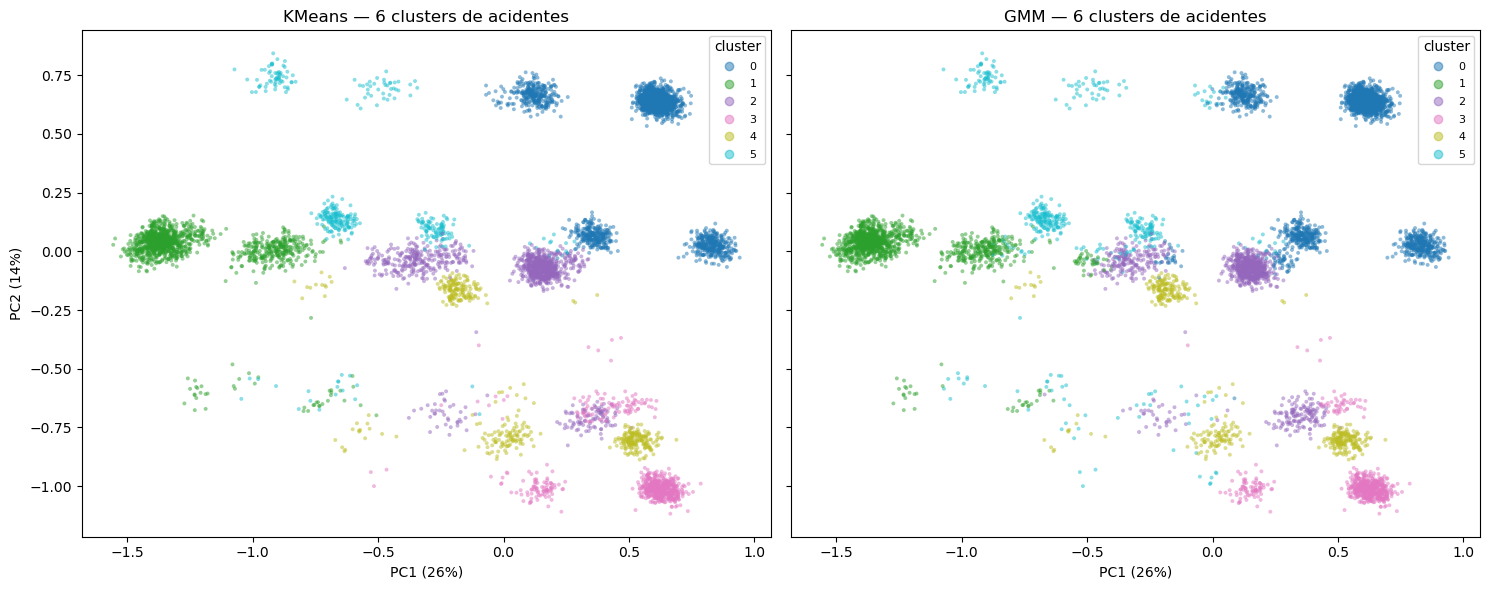

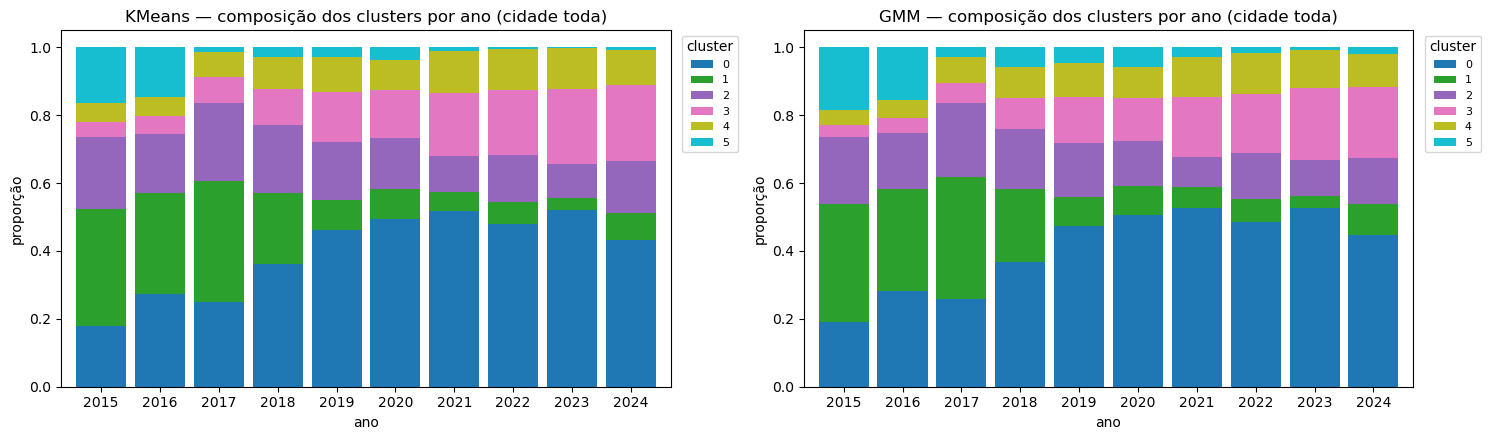


=== cluster_kmeans: 244 semáforos testados (>= 8 acidentes em cada período) ===
Mudaram além do calendário (q < 0.05): 0 | esperado por acaso ≈ 12 sem correção
codigo_semaforo  n_antes  n_depois  tvd_bruto  S_ajustado  p_sim  cluster_que_mais_subiu  cluster_que_mais_caiu  q_fdr  mudou_alem_do_calendario                                           cruzamento                  bairro
           1033       10        20      0.800       0.669  0.005                       0                      2  0.146                     False AV. DÉMETRIO MENEZES & PGV VAPT-VUPT ANTÔNIO BEZERRA         ANTÔNIO BEZERRA
            852        9        20      0.650       0.667  0.006                       2                      1  0.146                     False              R. JOAQUIM NABUCO & R. VICENTE LINHARES                 ALDEOTA
           1012       15        10      0.700       0.585  0.028                       0                      1  0.284                     False               AV. DES. GONZA

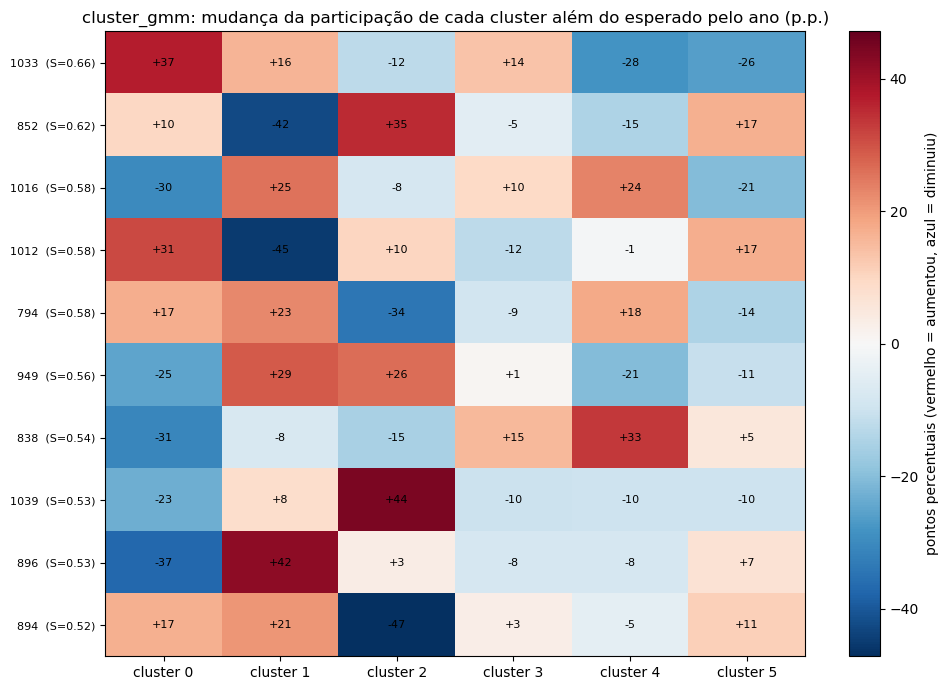

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# ---------------- PARÂMETROS ----------------
CAMINHO_ENTRADA = r"C:saida_semaforos_antes_depois.geojson"   # saída do semaforos_antes_depois.py
K_KMEANS, K_GMM = 6, 6             # inteiro, ou None para escolher por silhouette (KMeans) / BIC (GMM)
K_MIN, K_MAX    = 3, 8
VARIANCIA_PCA   = 0.90             # variância mantida na redução antes de clusterizar
N_INIT          = 5
REG_COVAR_GMM   = 0.05             # regularização do GMM (dados binários tornam o GMM instável sem isso)
AMOSTRA_SILHOUETTE = 5000          # nº de acidentes usados no cálculo do silhouette
MIN_ACIDENTES_PERIODO = 8          # mínimo de acidentes em cada período para testar o semáforo
N_SIMULACOES    = 1000             # simulações do teste (nulo = composição da cidade no mesmo ano)
ALFA            = 0.05             # nível de significância (após correção FDR)
MODELO_DETALHE  = "cluster_gmm"    # modelo usado no gráfico dos semáforos que mais mudaram
TOP_N           = 10               # nº de semáforos no gráfico de detalhe
AMOSTRA_PLOT    = 6000             # nº de acidentes plotados na projeção
SEMENTE         = 42
rng = np.random.default_rng(SEMENTE)

# ---------------- DADOS ----------------
g   = gpd.read_file(CAMINHO_ENTRADA)
aci = g[(g["tipo_feature"] == "acidente") & (g["periodo"].isin(["antes", "depois"]))].copy()
aci["codigo_semaforo"] = aci["codigo_semaforo"].astype(str)
aci = aci.reset_index(drop=True)
print("Colunas de acidentes:", [c for c in aci.dropna(axis=1, how="all").columns if c != "geometry"])
cols = {c.lower(): c for c in aci.columns}      # procura colunas sem diferenciar maiúscula/minúscula

# ---------------- ATRIBUTOS DOS ACIDENTES (one-hot) ----------------
nat = aci[cols["natureza"]].astype(str).str.strip().str.lower()
aci["natureza_grupo"] = np.select(
    [nat.str.startswith("atropelamento de animal"), nat.str.startswith("atropelamento"),
     nat.eq("colisão traseira"), nat.eq("colisão transversal"), nat.str.startswith("colisão lateral"),
     nat.eq("colisão frontal"), nat.eq("engavetamento"), nat.eq("colisão"),
     nat.str.startswith("queda"), nat.str.startswith("choque"),
     nat.isin(["capotamento", "tombamento"]), nat.eq("não informado")],
    ["outros", "atropelamento", "col_traseira", "col_transversal", "col_lateral",
     "col_frontal", "engavetamento", "colisao_generica",
     "queda", "choque", "capotamento", "natureza_ni"], default="outros")
aci["severidade_grupo"] = aci[cols["severidade"]].astype(str).str.strip().str.lower().replace(
    {"não informado": "sev_ni"})

if "hora" in cols:
    h = pd.to_numeric(aci[cols["hora"]].astype(str).str.split(":").str[0], errors="coerce")
    aci["faixa_hora"] = pd.cut(h, [-1, 5, 11, 17, 23], labels=["madrugada", "manha", "tarde", "noite"]).astype(str)
    aci.loc[h.isna(), "faixa_hora"] = "hora_ni"
else:
    print("[aviso] coluna HORA não encontrada — faixa de horário ignorada")

if "data_acidente" in cols:
    data = pd.to_datetime(aci[cols["data_acidente"]], errors="coerce")
else:
    data = pd.to_datetime(dict(year=aci[cols["ano"]], month=aci[cols["mes"]], day=aci[cols["dia"]]), errors="coerce")
aci["fim_de_semana"] = (data.dt.dayofweek >= 5).astype(float)
aci["ano_acidente"] = data.dt.year

veic = {"motocicleta": "moto", "automovel": "auto", "onibus": "onibus", "caminhao": "caminhao", "bicicleta": "bicicleta"}
for original, nome in veic.items():
    if original in cols:
        aci["v_" + nome] = (pd.to_numeric(aci[cols[original]], errors="coerce").fillna(0) > 0).astype(float)

categoricas = [c for c in ["natureza_grupo", "severidade_grupo", "faixa_hora"] if c in aci.columns]
binarias = ["fim_de_semana"] + [c for c in aci.columns if c.startswith("v_")]
Xdf = pd.concat([pd.get_dummies(aci[categoricas], dtype=float), aci[binarias]], axis=1)
print(f"{len(aci)} registros de acidentes, {Xdf.shape[1]} atributos")

# ajusta os modelos com cada acidente UMA vez (um acidente pode cair em mais de um retângulo)
chave_unica = aci[cols["cod_acidente"]] if "cod_acidente" in cols else aci.index
unico = ~pd.Series(chave_unica).duplicated().to_numpy()
pca_red = PCA(n_components=VARIANCIA_PCA, random_state=SEMENTE).fit(Xdf[unico])
Z = pca_red.transform(Xdf)
print(f"{len(np.where(unico)[0])} acidentes únicos | {Z.shape[1]} componentes mantêm {VARIANCIA_PCA:.0%} da variância")

# ---------------- ESCOLHA DE K ----------------
if K_KMEANS is None:
    amostra = rng.choice(np.where(unico)[0], size=min(AMOSTRA_SILHOUETTE, unico.sum()), replace=False)
    sil = {}
    for k in range(K_MIN, K_MAX + 1):
        rot = KMeans(k, n_init=N_INIT, random_state=SEMENTE).fit(Z[unico]).predict(Z[amostra])
        sil[k] = silhouette_score(Z[amostra], rot)
    K_KMEANS = max(sil, key=sil.get)
    print("KMeans silhouette:", {k: round(v, 3) for k, v in sil.items()}, "-> k =", K_KMEANS)
if K_GMM is None:
    bic = {k: GaussianMixture(k, covariance_type="diag", n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                              random_state=SEMENTE).fit(Z[unico]).bic(Z[unico]) for k in range(K_MIN, K_MAX + 1)}
    K_GMM = min(bic, key=bic.get)
    print("GMM BIC:", {k: round(v) for k, v in bic.items()}, "-> k =", K_GMM)

# ---------------- CLUSTERIZAÇÃO DOS ACIDENTES ----------------
km = KMeans(K_KMEANS, n_init=N_INIT, random_state=SEMENTE).fit(Z[unico])
gm = GaussianMixture(K_GMM, covariance_type="diag", n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                     random_state=SEMENTE).fit(Z[unico])
aci["cluster_kmeans"] = km.predict(Z)
aci["cluster_gmm"]    = gm.predict(Z)
aci["prob_gmm"]       = gm.predict_proba(Z).max(axis=1)

# renumera clusters por tamanho (0 = mais frequente)
for col in ["cluster_kmeans", "cluster_gmm"]:
    ordem = aci.loc[unico, col].value_counts().index
    aci[col] = aci[col].map({antigo: novo for novo, antigo in enumerate(ordem)})

# o que caracteriza cada cluster (os atributos mais característicos, com % no cluster vs % geral)
geral = Xdf[unico].mean()
for col in ["cluster_kmeans", "cluster_gmm"]:
    print(f"\n=== {col}: perfil dos clusters (atributo: % no cluster | % geral) ===")
    for c in sorted(aci[col].unique()):
        sel = unico & (aci[col] == c).to_numpy()
        pc = Xdf[sel].mean()
        top = (pc - geral).sort_values(ascending=False).head(5).index
        print(f"cluster {c} (n={sel.sum()}): " + "; ".join(f"{a} {pc[a]:.0%}|{geral[a]:.0%}" for a in top))

# ---------------- PROJEÇÃO (PCA 2D dos acidentes) ----------------
pca2 = PCA(n_components=2, random_state=SEMENTE).fit(Xdf[unico])
idx = rng.choice(np.where(unico)[0], size=min(AMOSTRA_PLOT, unico.sum()), replace=False)
P2 = pca2.transform(Xdf.iloc[idx]) + rng.normal(0, 0.03, (len(idx), 2))   # jitter: atributos são binários
fig, eixos = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for ax, col, titulo in zip(eixos, ["cluster_kmeans", "cluster_gmm"], ["KMeans", "GMM"]):
    pts = ax.scatter(P2[:, 0], P2[:, 1], c=aci[col].iloc[idx], cmap="tab10", s=8, alpha=0.5, edgecolor="none")
    ax.set_title(f"{titulo} — {aci[col].nunique()} clusters de acidentes")
    ax.set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})")
    ax.legend(*pts.legend_elements(), title="cluster", loc="best", fontsize=8)
eixos[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
plt.tight_layout()
plt.show()

# ---------------- DERIVA TEMPORAL: composição dos clusters por ano ----------------
# (se a composição muda muito de um ano para o outro na cidade toda, "antes x depois" fica contaminado pelo calendário)
fig, eixos = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, col, titulo in zip(eixos, ["cluster_kmeans", "cluster_gmm"], ["KMeans", "GMM"]):
    comp_ano = pd.crosstab(aci.loc[unico, "ano_acidente"], aci.loc[unico, col], normalize="index")
    comp_ano.plot.bar(stacked=True, ax=ax, colormap="tab10", width=0.85, rot=0)
    ax.set_title(f"{titulo} — composição dos clusters por ano (cidade toda)")
    ax.set_ylabel("proporção"); ax.set_xlabel("ano"); ax.legend(title="cluster", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# ---------------- POR SEMÁFORO: A COMPOSIÇÃO MUDOU ALÉM DO ESPERADO PELO ANO? ----------------
# Para cada semáforo: composição observada antes/depois  vs  composição esperada se ele seguisse a cidade
# (esperado = composição de clusters da cidade em cada ano em que ele teve acidentes).
#   mudança ajustada = (obs_depois - esp_depois) - (obs_antes - esp_antes)      [por cluster]
#   estatística S    = metade da soma dos |mudança ajustada|  (0 = nada além do calendário)
# p-valor: simula acidentes sorteando o cluster da composição da cidade no mesmo ano; correção FDR (Benjamini-Hochberg).
sem_pts = g[g["tipo_feature"] == "semaforo"].copy()                        # nome do cruzamento vem das features de semáforo
sem_pts["codigo_semaforo"] = sem_pts["codigo_semaforo"].astype(str)
cols_sem = {c.lower(): c for c in sem_pts.columns}
nome_sem = sem_pts.set_index("codigo_semaforo")[[cols_sem["cruzamento"], cols_sem["bairro"]]] \
    if ("cruzamento" in cols_sem and "bairro" in cols_sem) else None
resultados, ajustes = {}, {}
for modelo in ["cluster_kmeans", "cluster_gmm"]:
    K = aci[modelo].max() + 1
    P_ano = pd.crosstab(aci.loc[unico, "ano_acidente"], aci.loc[unico, modelo], normalize="index") \
              .reindex(columns=range(K), fill_value=0)
    linhas, mat = [], {}
    for cod, d in aci.dropna(subset=["ano_acidente"]).groupby("codigo_semaforo"):
        dep = (d["periodo"] == "depois").to_numpy()
        na, nd = int((~dep).sum()), int(dep.sum())
        if na < MIN_ACIDENTES_PERIODO or nd < MIN_ACIDENTES_PERIODO:
            continue
        M = np.eye(K)[d[modelo].to_numpy()]
        Pesp = P_ano.reindex(d["ano_acidente"].astype(int)).to_numpy()            # (n, K): esperado de cada acidente
        pa, pdp = M[~dep].mean(0), M[dep].mean(0)
        ea, ed = Pesp[~dep].mean(0), Pesp[dep].mean(0)
        ajuste = (pdp - ed) - (pa - ea)
        S = 0.5 * np.abs(ajuste).sum()
        cum = Pesp.cumsum(1)
        sim = np.minimum((rng.random((N_SIMULACOES, len(d)))[:, :, None] > cum[None]).sum(2), K - 1)
        Ms = np.eye(K)[sim]                                                       # (N, n, K)
        aj_s = (Ms[:, dep].mean(1) - ed) - (Ms[:, ~dep].mean(1) - ea)
        S_sim = 0.5 * np.abs(aj_s).sum(1)
        p = (1 + (S_sim >= S).sum()) / (1 + N_SIMULACOES)
        linhas.append({"codigo_semaforo": cod, "n_antes": na, "n_depois": nd,
                       "tvd_bruto": 0.5 * np.abs(pdp - pa).sum(), "S_ajustado": S, "p_sim": p,
                       "cluster_que_mais_subiu": ajuste.argmax(), "cluster_que_mais_caiu": ajuste.argmin()})
        mat[cod] = ajuste
    res = pd.DataFrame(linhas)
    ordem_p = res["p_sim"].argsort().to_numpy()                                   # FDR (Benjamini-Hochberg)
    m = len(res)
    q = np.empty(m)
    q[ordem_p] = np.minimum.accumulate((res["p_sim"].to_numpy()[ordem_p] * m / np.arange(1, m + 1))[::-1])[::-1]
    res["q_fdr"] = np.minimum(q, 1)
    res["mudou_alem_do_calendario"] = res["q_fdr"] < ALFA
    if nome_sem is not None:
        res = res.merge(nome_sem.rename(columns={cols_sem["cruzamento"]: "cruzamento", cols_sem["bairro"]: "bairro"}),
                        left_on="codigo_semaforo", right_index=True, how="left")
    resultados[modelo] = res.sort_values("S_ajustado", ascending=False).reset_index(drop=True)
    ajustes[modelo] = pd.DataFrame(mat, index=range(K)).T

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", None)
for modelo, res in resultados.items():
    print(f"\n=== {modelo}: {len(res)} semáforos testados (>= {MIN_ACIDENTES_PERIODO} acidentes em cada período) ===")
    print(f"Mudaram além do calendário (q < {ALFA}): {res['mudou_alem_do_calendario'].sum()} "
          f"| esperado por acaso ≈ {ALFA * len(res):.0f} sem correção")
    print(res.head(15).round(3).to_string(index=False))

# ---------------- DETALHE: mudança ajustada por cluster nos semáforos de maior S ----------------
res = resultados[MODELO_DETALHE]
top = res[res["mudou_alem_do_calendario"]].head(TOP_N)
if top.empty:
    top = res.head(TOP_N)
    print(f"\nNenhum semáforo significativo em {MODELO_DETALHE}; mostrando os {TOP_N} de maior S (sem significância).")
H = ajustes[MODELO_DETALHE].loc[top["codigo_semaforo"]] * 100
lim = max(abs(H.to_numpy()).max(), 1)
fig, ax = plt.subplots(figsize=(1.0 * H.shape[1] + 4, 0.5 * len(H) + 2))
im = ax.imshow(H.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        ax.text(j, i, f"{H.iloc[i, j]:+.0f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels([f"cluster {c}" for c in H.columns])
ax.set_yticks(range(len(H))); ax.set_yticklabels([f"{c}  (S={s:.2f})" for c, s in zip(top["codigo_semaforo"], top["S_ajustado"])], fontsize=8)
ax.set_title(f"{MODELO_DETALHE}: mudança da participação de cada cluster além do esperado pelo ano (p.p.)")
plt.colorbar(im, ax=ax, label="pontos percentuais (vermelho = aumentou, azul = diminuiu)")
plt.tight_layout()
plt.show()

#anotações: 
# PC1 (horizontal) — gravidade / tipo de veículo e de colisão
#   direita  = acidentes com ferido, com moto, colisão sem tipo especificado (e, mais fraco, queda)
#   esquerda = acidentes sem ferido (ileso), com carro, colisões entre veículos (traseira, lateral, transversal)

# PC2 (vertical) — horário
#   cima   = tarde
#   centro = noite e madrugada
#   baixo  = manhã

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box
from shapely import affinity

# ---- caminhos (use r"..." no Windows) ----
CAMINHO_SINISTROS = r"sinistros-2015-2024.geojson"
CAMINHO_SEMAFOROS = r"dadosabertos_semaforosctafor.geojson"
CAMINHO_BAIRROS   = r"bairros.geojson"   # polígonos dos bairros (o arquivo de sinistros não tem coluna de bairro)
COLUNA_BAIRRO     = "nome"
# ---- análises ----
TOP_N = 5
SEPARAR_MADRUGADA = False      # False: noite = 18h–5h59 | True: madrugada (0h–5h59) vira uma 4ª faixa

# ---- impacto dos semáforos ----
JANELA_ANOS = 2
MIN_ACIDENTES_ANTES = 5        # semáforos com menos acidentes que isso no "antes" ficam fora do ranking de % (evita 1 -> 0 = -100%)
COMPRIMENTO_METADE_M = 100     # retângulo em volta do semáforo (metade do comprimento, m)
LARGURA_METADE_M = 30          # metade da largura, m
ROTACAO_GRAUS = "auto"         # "auto" alinha o retângulo com a direção dos acidentes ao redor; ou um número (0 = leste-oeste)
RAIO_AUTO_M, MIN_ACIDENTES_AUTO = 100, 5
CRS_METRICO = "EPSG:31984"     # SIRGAS 2000 / UTM 24S

aci = gpd.read_file(CAMINHO_SINISTROS)
import json
if not any("hora" in c.lower() for c in aci.columns):          # o geopandas descartou o horário: lê direto do JSON
    with open(CAMINHO_SINISTROS, encoding="utf-8") as f:
        raw = pd.DataFrame([ft["properties"] for ft in json.load(f)["features"]])
    print("Colunas de horário no arquivo bruto:", [c for c in raw.columns if "hora" in c.lower()])
    if len(raw) == len(aci):
        aci["HORA"] = raw["HORA"].to_numpy()
sem = gpd.read_file(CAMINHO_SEMAFOROS)
aci["data"] = pd.to_datetime(dict(year=aci["ANO"], month=aci["MES"], day=aci["DIA"]), errors="coerce")
aci = aci.dropna(subset=["data"]).reset_index(drop=True)
print(f"{len(aci)} acidentes de {aci['data'].min().date()} a {aci['data'].max().date()} | {len(sem)} semáforos")

# ---- limpeza dos nomes de logradouro (LOG1 / LOG2) ----
# o arquivo mistura maiúsculas/minúsculas, acentos, vírgula no final e abreviações
prefixos = {"AV": "AVENIDA", "AVE": "AVENIDA", "R": "RUA", "TV": "TRAVESSA", "TRAV": "TRAVESSA", "AL": "ALAMEDA",
            "PC": "PRACA", "PCA": "PRACA", "ROD": "RODOVIA", "RD": "RODOVIA", "EST": "ESTRADA", "VLA": "VILA"}
titulos = {"DR": "DOUTOR", "PROF": "PROFESSOR", "CEL": "CORONEL", "GAL": "GENERAL", "SEN": "SENADOR",
           "DEP": "DEPUTADO", "ENG": "ENGENHEIRO", "PRES": "PRESIDENTE", "MAL": "MARECHAL", "ALM": "ALMIRANTE",
           "CAP": "CAPITAO", "STA": "SANTA", "STO": "SANTO", "MONS": "MONSENHOR", "DES": "DESEMBARGADOR"}
for col in ["LOG1", "LOG2"]:
    s = (aci[col].astype(str).str.normalize("NFKD").str.encode("ascii", "ignore").str.decode("ascii").str.upper())
    s = s.str.replace(r"[,;.]+", " ", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
    for abrev, cheio in prefixos.items():
        s = s.str.replace(rf"^{abrev} ", f"{cheio} ", regex=True)
    for abrev, cheio in titulos.items():
        s = s.str.replace(rf"\b{abrev}\b", cheio, regex=True)
    s = s.where(~s.isin(["", "NAO INFORMADO", "NAN", "NONE"]))
    aci[col + "_n"] = s
print("LOG1: nomes distintos antes/depois da limpeza:", aci["LOG1"].nunique(), "->", aci["LOG1_n"].nunique())
print(f"LOG1 informado em {aci['LOG1_n'].notna().mean():.0%} dos acidentes | LOG2 informado em {aci['LOG2_n'].notna().mean():.0%}")

Skipping field HORA: unsupported OGR type: 10


Colunas de horário no arquivo bruto: ['HORA']
130823 acidentes de 2015-01-01 a 2024-12-31 | 1231 semáforos
LOG1: nomes distintos antes/depois da limpeza: 41243 -> 38081
LOG1 informado em 100% dos acidentes | LOG2 informado em 36%


Acidentes fora de qualquer bairro do arquivo: 686 (0.5%)

=== 5 bairros com MAIS acidentes ===


,acidentes,% do total,área (km²),acidentes/km²
bairro,,,,
CENTRO,7464,5.71,4.89,1526.0
ALDEOTA,5284,4.04,3.88,1363.0
MEIRELES,4098,3.13,2.66,1540.0
PARANGABA,3524,2.69,4.04,871.0
FÁTIMA,3378,2.58,2.86,1181.0


=== 5 bairros com MENOS acidentes ===


,acidentes,% do total,área (km²),acidentes/km²
bairro,,,,
DE LOURDES,86,0.07,1.37,63.0
CIDADE 2000,89,0.07,0.50,179.0
SÃO BENTO,105,0.08,2.20,48.0
PARQUE PRESIDENTE VARGAS,114,0.09,1.54,74.0
COUTO FERNANDES,131,0.10,0.32,408.0


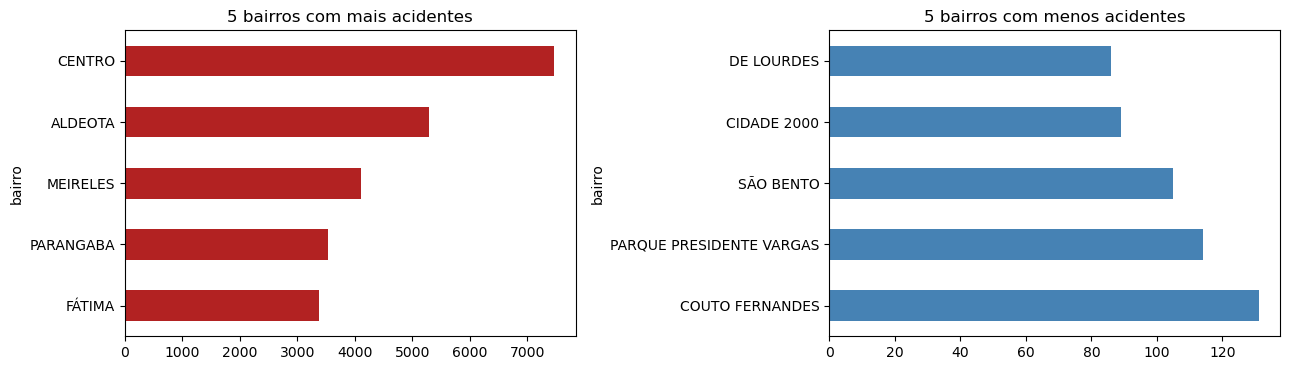

In [ ]:
bairros = gpd.read_file(CAMINHO_BAIRROS)
bairros = bairros[bairros.geometry.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(aci.crs)   # ignora os pontos (rótulos) do arquivo
junta = gpd.sjoin(aci[["COD_ACIDENTE", "geometry"]], bairros[[COLUNA_BAIRRO, "geometry"]], how="left", predicate="within")
junta = junta.drop_duplicates("COD_ACIDENTE")                      # ponto em cima da divisa de dois bairros
aci["bairro"] = aci["COD_ACIDENTE"].map(junta.set_index("COD_ACIDENTE")[COLUNA_BAIRRO])
sem_bairro = aci["bairro"].isna().sum()
print(f"Acidentes fora de qualquer bairro do arquivo: {sem_bairro} ({sem_bairro / len(aci):.1%})")

por_bairro = aci["bairro"].value_counts().reindex(bairros[COLUNA_BAIRRO].unique(), fill_value=0).sort_values(ascending=False)
area_km2 = bairros.to_crs(CRS_METRICO).set_index(COLUNA_BAIRRO).geometry.area / 1e6
tab = lambda s: pd.DataFrame({"acidentes": s, "% do total": (s / len(aci) * 100).round(2),
                              "área (km²)": area_km2.reindex(s.index).round(2),
                              "acidentes/km²": (s / area_km2.reindex(s.index)).round(0)})
print(f"\n=== {TOP_N} bairros com MAIS acidentes ===")
display(tab(por_bairro.head(TOP_N)))
print(f"=== {TOP_N} bairros com MENOS acidentes ===")
display(tab(por_bairro.sort_values().head(TOP_N)))

fig, eixos = plt.subplots(1, 2, figsize=(13, 3.8))
por_bairro.head(TOP_N)[::-1].plot.barh(ax=eixos[0], color="firebrick", title=f"{TOP_N} bairros com mais acidentes")
por_bairro.sort_values().head(TOP_N)[::-1].plot.barh(ax=eixos[1], color="steelblue", title=f"{TOP_N} bairros com menos acidentes")
plt.tight_layout(); plt.show()

,acidentes,%
periodo_dia,,
madrugada (0h–5h59),18585,14.2
manhã (6h–11h59),41864,32.0
tarde (12h–17h59),45401,34.7
noite (18h–23h59),24973,19.1


Acidentes sem horário válido: 0


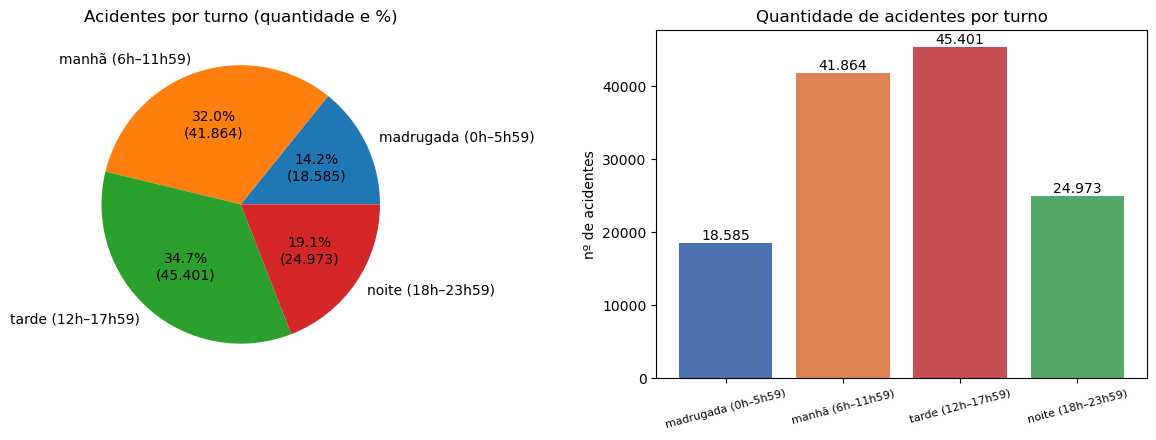

In [ ]:
col_hora = next((c for c in aci.columns if "hora" in c.lower()), None)
if col_hora is None:
    raise KeyError("Nenhuma coluna de horário encontrada — veja as colunas do arquivo.")
hora = pd.to_numeric(aci[col_hora].astype(str).str.split(":").str[0], errors="coerce")

faixas = ["madrugada (0h–5h59)", "manhã (6h–11h59)", "tarde (12h–17h59)", "noite (18h–23h59)"]
aci["periodo_dia"] = pd.cut(hora, bins=[-1, 5, 11, 17, 23], labels=faixas)

dist = aci["periodo_dia"].value_counts().reindex(faixas)
display(pd.DataFrame({"acidentes": dist, "%": (dist / dist.sum() * 100).round(1)}))
print(f"Acidentes sem horário válido: {hora.isna().sum()}")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))
dist.plot.pie(ax=eixos[0], ylabel="", title="Acidentes por turno (quantidade e %)",
              autopct=lambda p: f"{p:.1f}%\n({p * dist.sum() / 100:,.0f})".replace(",", "."))
barras = eixos[1].bar(range(len(dist)), dist.values, color=["#4c72b0", "#dd8452", "#c44e52", "#55a868"])
eixos[1].bar_label(barras, labels=[f"{v:,.0f}".replace(",", ".") for v in dist.values])
eixos[1].set_xticks(range(len(dist))); eixos[1].set_xticklabels(faixas, rotation=15, fontsize=8)
eixos[1].set_ylabel("nº de acidentes"); eixos[1].set_title("Quantidade de acidentes por turno")
plt.tight_layout(); plt.show()

=== 5 logradouros (LOG1) com mais acidentes ===


,acidentes,% do total
LOG1_n,,
RODOVIA CE-040,2035,1.56
AVENIDA GENERAL OSORIO DE PAIVA,919,0.70
AVENIDA SANTOS DUMONT,715,0.55
AVENIDA SENADOR CARLOS JEREISSATI (AEROPORTO),705,0.54
AVENIDA DOUTOR SILAS MUNGUBA,682,0.52


=== 5 combinações LOG1 × LOG2 com mais acidentes (base: 46855 acidentes = 36% do total) ===


,acidentes,% da base com LOG2
AVENIDA DESEMBARGADOR GONZAGA × AVENIDA OLIVEIRA PAIVA,83,0.18
AVENIDA GODOFREDO MACIEL × RUA NEREU RAMOS,80,0.17
AVENIDA GENERAL MURILO BORGES × AVENIDA GOV RAUL BARBOSA,76,0.16
AVENIDA ABOLICAO × AVENIDA DESEMBARGADOR MOREIRA,75,0.16
AVENIDA ANTONIO SALES × RUA NUNES VALENTE,70,0.15


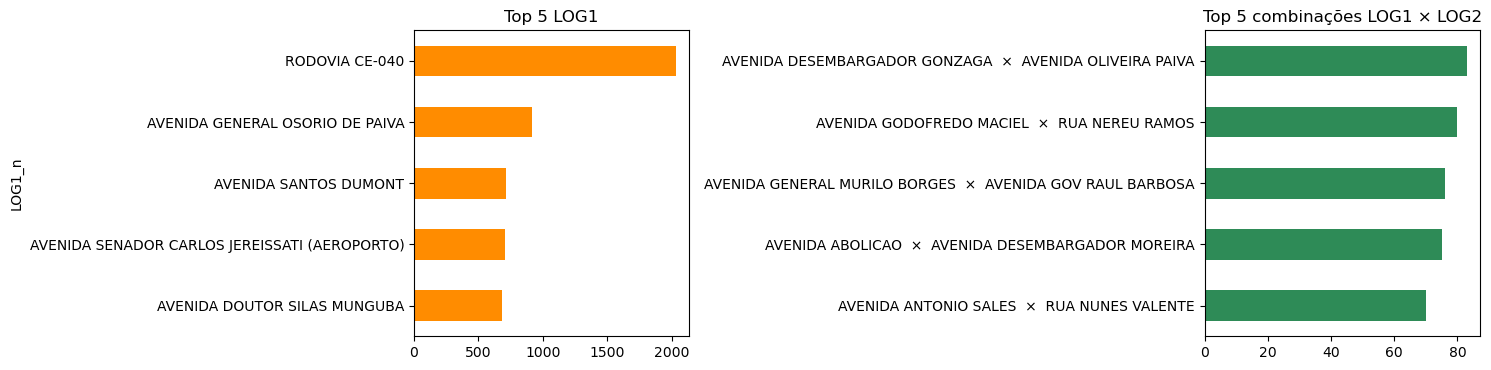

In [ ]:
top_log = aci["LOG1_n"].value_counts().head(TOP_N)
print(f"=== {TOP_N} logradouros (LOG1) com mais acidentes ===")
display(pd.DataFrame({"acidentes": top_log, "% do total": (top_log / len(aci) * 100).round(2)}))

# combinação sem ordem: "A x B" é o mesmo cruzamento que "B x A"; só entram acidentes com LOG1 e LOG2 informados e diferentes
v = aci.dropna(subset=["LOG1_n", "LOG2_n"])
v = v[v["LOG1_n"] != v["LOG2_n"]]
par = np.where(v["LOG1_n"] < v["LOG2_n"], v["LOG1_n"] + "  ×  " + v["LOG2_n"], v["LOG2_n"] + "  ×  " + v["LOG1_n"])
top_par = pd.Series(par).value_counts().head(TOP_N)
print(f"=== {TOP_N} combinações LOG1 × LOG2 com mais acidentes (base: {len(v)} acidentes = {len(v) / len(aci):.0%} do total) ===")
display(pd.DataFrame({"acidentes": top_par, "% da base com LOG2": (top_par / len(v) * 100).round(2)}))

fig, eixos = plt.subplots(1, 2, figsize=(15, 3.8))
top_log[::-1].plot.barh(ax=eixos[0], color="darkorange", title=f"Top {TOP_N} LOG1")
top_par[::-1].plot.barh(ax=eixos[1], color="seagreen", title=f"Top {TOP_N} combinações LOG1 × LOG2")
plt.tight_layout(); plt.show()

Semáforos com data de implantação: 856 | com janela de 2 anos completa antes e depois: 279

279 semáforos analisados | 223 com >= 5 acidentes no antes (entram no ranking)
Total nos 279 semáforos: antes = 3056 | depois = 1936 (-36.6%) | cidade nas mesmas janelas: mediana -22.2%


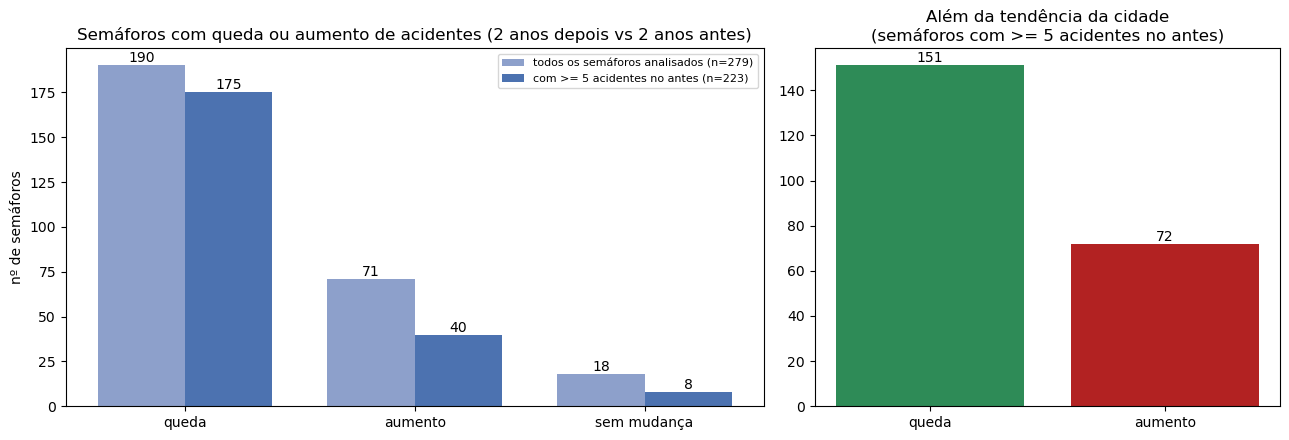


=== Quantos semáforos tiveram queda e quantos tiveram aumento ===


,todos os semáforos analisados,com >= 5 acidentes no antes
queda,190,175
aumento,71,40
sem mudança,18,8
total,279,223
queda além da cidade,<NA>,151
aumento além da cidade,<NA>,72


todos os semáforos analisados: 190 com queda (68%) | 71 com aumento (25%)
com >= 5 acidentes no antes: 175 com queda (78%) | 40 com aumento (18%)

=== 5 locais onde MAIS DIMINUÍRAM os acidentes (maior queda %) ===


,codigo,logradouro/cruzamento,bairro,implantacao,antes,depois,var_%,cidade_var_%,var_ajustada_%
114,1010,R. MONSENHOR CATÃO & R. EDUARDO GARCIA,ALDEOTA,2018-12-14,8,0,-100.0,-27.0,-100.0
144,1042,R. CEL. FRANCISCO PEREIRA & R. PERGENTINO MAIA,MESSEJANA,2019-04-12,25,0,-100.0,-23.1,-100.0
223,1130,R. ARI MAIA & R. OSCAR ARARIPE,GRANJA LISBOA,2020-03-18,12,0,-100.0,-14.6,-100.0
254,1166,AV. I (JOSÉ WALTER) & AV. G (JOSÉ WALTER),PREFEITO JOSÉ WALTER,2021-02-10,17,1,-94.1,0.8,-94.2
211,1118,R. BR. DE AQUIRAZ & R. DR. MIGUEL COUTO,MESSEJANA,2020-02-19,16,1,-93.8,-16.1,-92.6


=== 5 locais onde MAIS AUMENTARAM os acidentes ===


,codigo,logradouro/cruzamento,bairro,implantacao,antes,depois,var_%,cidade_var_%,var_ajustada_%
222,1129,R. SARGENTO JOÃO PINHEIRO & R. OSCAR ARARIPE,GRANJA LISBOA,2020-04-23,6,29,383.3,-10.7,441.1
239,1146,AV. HUMBERTO MONTE & R. PE. GUERRA,PARQUELÂNDIA,2020-10-02,5,14,180.0,0.2,179.5
233,1140,AV. JOSÉ BASTOS & R. ANTÔNIO MARTINS,RODOLFO TEÓFILO,2020-10-10,9,25,177.8,0.7,175.8
14,861,AV. GAL. OSÓRIO DE PAIVA & R. LEBLON MAIA,VILA PERI,2018-08-03,7,18,157.1,-29.4,264.3
189,1094,R. ADRIANO MARTINS & AV. PRES. CASTELO BRANCO,JACARECANGA,2019-11-22,6,14,133.3,-17.3,182.3


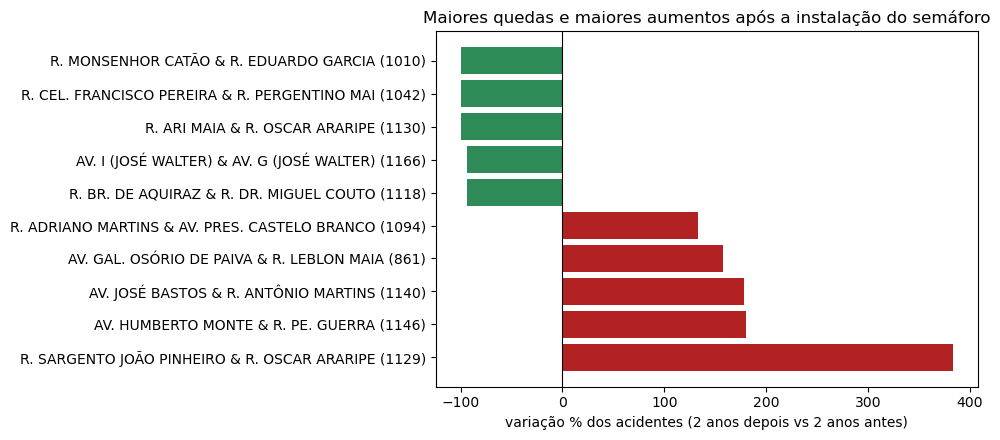

In [ ]:
# Para cada semáforo: acidentes dentro de um retângulo em volta dele, nos 2 anos antes e nos 2 anos depois da implantação.
# Só entram semáforos com a janela completa dentro do período dos dados (e ainda ativos ao fim dos 2 anos).
sem["d0"] = pd.to_datetime(sem["DATA_IMPLANTAÇÃO"], format="%d/%m/%Y", errors="coerce")
sem["dd"] = pd.to_datetime(sem["DATA_DESATIVAÇÃO"], format="%d/%m/%Y", errors="coerce")
jan = pd.Timedelta(days=int(JANELA_ANOS * 365.25))
ini, fim = aci["data"].min(), aci["data"].max()
elegiveis = sem.dropna(subset=["d0"])
elegiveis = elegiveis[(elegiveis["d0"] - jan >= ini) & (elegiveis["d0"] + jan <= fim)
                      & (elegiveis["dd"].isna() | (elegiveis["dd"] >= elegiveis["d0"] + jan))].copy()
print(f"Semáforos com data de implantação: {sem['d0'].notna().sum()} | com janela de {JANELA_ANOS} anos completa antes e depois: {len(elegiveis)}")

aci_m = aci.to_crs(CRS_METRICO)
sem_m = elegiveis.to_crs(CRS_METRICO)
X, Y = aci_m.geometry.x.to_numpy(), aci_m.geometry.y.to_numpy()
datas = aci["data"].to_numpy()
datas_ord = np.sort(datas)
linhas = []
for (_, r), p in zip(sem_m.iterrows(), sem_m.geometry):
    # direção do retângulo
    ang = ROTACAO_GRAUS
    if ang == "auto":
        cand = aci_m.sindex.query(p.buffer(RAIO_AUTO_M))
        dx, dy = X[cand] - p.x, Y[cand] - p.y
        perto = np.hypot(dx, dy) <= RAIO_AUTO_M
        if perto.sum() >= MIN_ACIDENTES_AUTO:
            vals, vecs = np.linalg.eigh(np.cov(np.column_stack([dx[perto], dy[perto]]).T))
            ang = float(np.degrees(np.arctan2(vecs[1, vals.argmax()], vecs[0, vals.argmax()])) % 180)
        else:
            ang = 0
    ret = affinity.rotate(box(p.x - COMPRIMENTO_METADE_M, p.y - LARGURA_METADE_M,
                              p.x + COMPRIMENTO_METADE_M, p.y + LARGURA_METADE_M), ang, origin=p)
    dt = datas[aci_m.sindex.query(ret, predicate="contains")]
    d0 = np.datetime64(r["d0"])
    antes = int(((dt >= d0 - np.timedelta64(jan.days, "D")) & (dt < d0)).sum())
    depois = int(((dt > d0) & (dt <= d0 + np.timedelta64(jan.days, "D"))).sum())
    # referência: o que aconteceu na cidade toda nas mesmas duas janelas
    c_ant = np.searchsorted(datas_ord, d0, "left") - np.searchsorted(datas_ord, d0 - np.timedelta64(jan.days, "D"), "left")
    c_dep = np.searchsorted(datas_ord, d0 + np.timedelta64(jan.days, "D"), "right") - np.searchsorted(datas_ord, d0, "right")
    linhas.append({"codigo": r["CÓDIGO"], "logradouro/cruzamento": r["CRUZAMENTO"], "bairro": r["BAIRRO"],
                   "implantacao": r["d0"].date(), "antes": antes, "depois": depois,
                   "var_%": (depois - antes) / antes * 100 if antes else np.nan,
                   "cidade_var_%": (c_dep - c_ant) / c_ant * 100})
imp = pd.DataFrame(linhas)
imp["var_ajustada_%"] = ((1 + imp["var_%"] / 100) / (1 + imp["cidade_var_%"] / 100) - 1) * 100   # variação além da tendência da cidade
rank = imp[imp["antes"] >= MIN_ACIDENTES_ANTES].sort_values("var_%")
print(f"\n{len(imp)} semáforos analisados | {len(rank)} com >= {MIN_ACIDENTES_ANTES} acidentes no antes (entram no ranking)")
print(f"Total nos {len(imp)} semáforos: antes = {imp['antes'].sum()} | depois = {imp['depois'].sum()} "
      f"({(imp['depois'].sum() / imp['antes'].sum() - 1) * 100:+.1f}%) | cidade nas mesmas janelas: mediana {imp['cidade_var_%'].median():+.1f}%")
# gráfico: quantos semáforos tiveram queda, aumento ou sem mudança
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
cats = ["queda", "aumento", "sem mudança"]
larg = 0.38
for i, (nome, cor) in enumerate(zip(resumo.columns[:2], ["#8da0cb", "#4c72b0"])):
    vals = [int(resumo.loc[c, nome]) for c in cats]
    barras = eixos[0].bar(np.arange(3) + (i - 0.5) * larg, vals, larg, label=f"{nome} (n={int(resumo.loc['total', nome])})", color=cor)
    eixos[0].bar_label(barras)
eixos[0].set_xticks(range(3)); eixos[0].set_xticklabels(cats)
eixos[0].set_ylabel("nº de semáforos"); eixos[0].legend(fontsize=8)
eixos[0].set_title(f"Semáforos com queda ou aumento de acidentes ({JANELA_ANOS} anos depois vs {JANELA_ANOS} anos antes)")
nome = resumo.columns[1]
vals = [int(resumo.loc["queda além da cidade", nome]), int(resumo.loc["aumento além da cidade", nome])]
barras = eixos[1].bar(["queda", "aumento"], vals, color=["seagreen", "firebrick"])
eixos[1].bar_label(barras)
eixos[1].set_title("Além da tendência da cidade\n(semáforos com >= %d acidentes no antes)" % MIN_ACIDENTES_ANTES)
plt.tight_layout(); plt.show()
pd.set_option("display.width", 220)
# contagem de semáforos com queda, aumento ou sem mudança (depois x antes)
contagem = lambda d: pd.Series({"queda": int((d["depois"] < d["antes"]).sum()),
                                "aumento": int((d["depois"] > d["antes"]).sum()),
                                "sem mudança": int((d["depois"] == d["antes"]).sum()), "total": len(d)})
resumo = pd.DataFrame({"todos os semáforos analisados": contagem(imp),
                       f"com >= {MIN_ACIDENTES_ANTES} acidentes no antes": contagem(rank)})
resumo.loc["queda além da cidade"] = [np.nan, int((rank["var_ajustada_%"] < 0).sum())]
resumo.loc["aumento além da cidade"] = [np.nan, int((rank["var_ajustada_%"] > 0).sum())]
print("\n=== Quantos semáforos tiveram queda e quantos tiveram aumento ===")
display(resumo.astype("Int64"))
for nome in resumo.columns[:2]:
    q, a, t = int(resumo.loc["queda", nome]), int(resumo.loc["aumento", nome]), int(resumo.loc["total", nome])
    print(f"{nome}: {q} com queda ({q / t:.0%}) | {a} com aumento ({a / t:.0%})")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)
fmt = lambda d: d.round({"var_%": 1, "cidade_var_%": 1, "var_ajustada_%": 1})
print(f"\n=== {TOP_N} locais onde MAIS DIMINUÍRAM os acidentes (maior queda %) ===")
display(fmt(rank.head(TOP_N)))
print(f"=== {TOP_N} locais onde MAIS AUMENTARAM os acidentes ===")
display(fmt(rank.tail(TOP_N).iloc[::-1]))

fig, ax = plt.subplots(figsize=(10, 4.5))
graf = pd.concat([rank.head(TOP_N), rank.tail(TOP_N)])
ax.barh(graf["logradouro/cruzamento"].str.slice(0, 45) + " (" + graf["codigo"].astype(str) + ")", graf["var_%"],
        color=np.where(graf["var_%"] < 0, "seagreen", "firebrick"))
ax.axvline(0, color="k", lw=0.8); ax.invert_yaxis()
ax.set_xlabel(f"variação % dos acidentes ({JANELA_ANOS} anos depois vs {JANELA_ANOS} anos antes)")
ax.set_title("Maiores quedas e maiores aumentos após a instalação do semáforo")
plt.tight_layout(); plt.show()

#anotação:  
# variação do semáforo descontando o que aconteceu na cidade toda no mesmo período. A ideia é separar o que pode ser efeito local do que é apenas uma tendência geral de queda ou alta de acidentes.

# Como é calculado
# Para cada semáforo, o código mede duas variações, nas mesmas duas janelas de 2 anos antes e depois da instalação dele:

# var_%: a variação dos acidentes na área do semáforo.
# cidade_var_%: a variação dos acidentes na cidade inteira.

# A variação ajustada é:

# var_ajustada_% = (1 + var_%) / (1 + cidade_var_%) − 1

# Ela diz se o semáforo se saiu melhor ou pior que a cidade. Negativa significa que a área caiu mais (ou subiu menos) que a cidade. Positiva significa que caiu menos (ou subiu mais).

# Exemplo hipotético: um semáforo passa de 20 para 14 acidentes (−30%), mas a cidade caiu 40% no mesmo período. Ajustado: 0,70 / 0,60 − 1 = +16,7%. A área “melhorou” na contagem bruta, mas menos que a cidade, então não há queda além da tendência.

# Exemplo real do seu arquivo: o semáforo 861 (Av. Gal. Osório de Paiva × R. Leblon Maia) foi de 7 para 18 acidentes (+157%), enquanto a cidade caiu 29%. Ajustado: +264%. Ele subiu muito mais do que o contexto geral sugeriria.

# Por que isso importa
# Os acidentes caíram bastante na cidade ao longo do período, com mediana de −22% nas janelas analisadas. Sem o ajuste, quase todo semáforo pareceria “ter funcionado”, mesmo sem efeito nenhum. Por isso, dos 175 semáforos com queda bruta, só 151 caíram além da cidade.

# Limites do ajuste

# A queda da cidade pode ser, em parte, mudança no jeito de registrar acidentes, e não queda real. Nos seus dados, por exemplo, a parcela de acidentes sem ferido caiu bastante entre 2015 e 2021.
# Ele não corrige a regressão à média. Semáforos costumam ser instalados onde os acidentes estavam excepcionalmente altos, e esses locais tendem a cair de qualquer forma.
# Com poucos acidentes na área, a variação oscila por acaso, e o ajuste não elimina isso.

# O ajuste é uma comparação de contexto, não uma prova de efeito. Um grupo de controle, com cruzamentos parecidos sem semáforo novo, daria uma comparação mais forte.

[aviso] coluna HORA não encontrada neste arquivo — o horário não entra nos clusters
Acidentes no 'antes': 10045 registros (9379 acidentes únicos) em 427 semáforos
22 atributos -> 18 componentes (95% da variância)

Certeza média da atribuição: 1.00 | acidentes com certeza < 0,9: 0.2%

=== Clusters do ANTES — perfil (atributo: % no cluster | % geral do antes) ===
cluster 0 (n=2961, 32%): natureza_grupo_colisao_generica 100%|38%; severidade_grupo_ferido 83%|60%; v_moto 65%|50%; fim_de_semana 28%|25%; natureza_grupo_capotamento 0%|0%
cluster 1 (n=2249, 24%): natureza_grupo_col_transversal 57%|17%; natureza_grupo_col_lateral 43%|16%; v_auto 94%|69%; severidade_grupo_ileso 48%|30%; v_moto 52%|50%
cluster 2 (n=1948, 21%): natureza_grupo_col_traseira 45%|10%; severidade_grupo_sev_ni 36%|9%; v_onibus 30%|7%; severidade_grupo_ileso 42%|30%; v_auto 76%|69%
cluster 3 (n=1189, 13%): v_caminhao 25%|3%; v_bicicleta 18%|2%; natureza_grupo_choque 13%|2%; severidade_grupo_fatal 13%|2%; natureza_grupo_co

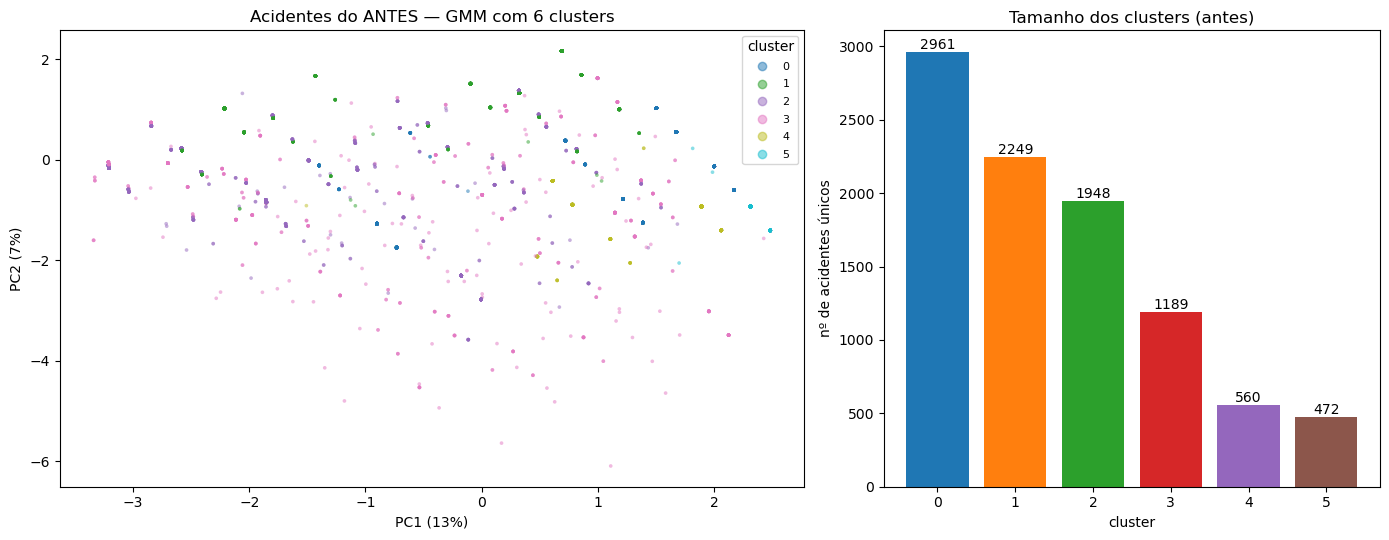

In [31]:

from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------- PARÂMETROS ----------------
CAMINHO_ENTRADA = r"saida_semaforos_antes_depois.geojson"   # saída do semaforos_antes_depois.py (retângulos + acidentes)
K_GMM = 6                      # nº de clusters; None = escolhe pelo BIC entre K_MIN e K_MAX
K_MIN, K_MAX = 3, 10
COVARIANCIA_GMM = "diag"
REG_COVAR_GMM = 0.05
N_INIT = 5
ESCALAR = True                 # mesmo peso para todos os atributos (senão os raros, como "fatal", praticamente somem)
VARIANCIA_PCA = 0.95           # variância mantida na redução antes do GMM
USAR_HORA = True               # False: o horário não participa dos clusters
AMOSTRA_PLOT = 5000
SEMENTE = 42
rng = np.random.default_rng(SEMENTE)

# ---------------- DADOS ----------------
g = gpd.read_file(CAMINHO_ENTRADA)
aci = g[(g["tipo_feature"] == "acidente") & (g["periodo"].isin(["antes", "depois"]))].copy().reset_index(drop=True)
aci["codigo_semaforo"] = aci["codigo_semaforo"].astype(str)
cols = {c.lower(): c for c in aci.columns}

# ---------------- ATRIBUTOS (calculados para antes E depois; o ajuste do modelo usa só o "antes") ----------------
nat = aci[cols["natureza"]].astype(str).str.strip().str.lower()
aci["natureza_grupo"] = np.select(
    [nat.str.startswith("atropelamento de animal"), nat.str.startswith("atropelamento"),
     nat.eq("colisão traseira"), nat.eq("colisão transversal"), nat.str.startswith("colisão lateral"),
     nat.eq("colisão frontal"), nat.eq("engavetamento"), nat.eq("colisão"),
     nat.str.startswith("queda"), nat.str.startswith("choque"),
     nat.isin(["capotamento", "tombamento"]), nat.eq("não informado")],
    ["outros", "atropelamento", "col_traseira", "col_transversal", "col_lateral",
     "col_frontal", "engavetamento", "colisao_generica",
     "queda", "choque", "capotamento", "natureza_ni"], default="outros")
aci["severidade_grupo"] = aci[cols["severidade"]].astype(str).str.strip().str.lower().replace({"não informado": "sev_ni"})
categoricas = ["natureza_grupo", "severidade_grupo"]
if USAR_HORA and "hora" in cols:
    h = pd.to_numeric(aci[cols["hora"]].astype(str).str.split(":").str[0], errors="coerce")
    aci["faixa_hora"] = pd.cut(h, [-1, 5, 11, 17, 23], labels=["madrugada", "manha", "tarde", "noite"]).astype(str)
    aci.loc[h.isna(), "faixa_hora"] = "hora_ni"
    categoricas.append("faixa_hora")
elif USAR_HORA:
    print("[aviso] coluna HORA não encontrada neste arquivo — o horário não entra nos clusters")
data = pd.to_datetime(aci[cols["data_acidente"]], errors="coerce") if "data_acidente" in cols else \
       pd.to_datetime(dict(year=aci[cols["ano"]], month=aci[cols["mes"]], day=aci[cols["dia"]]), errors="coerce")
aci["fim_de_semana"] = (data.dt.dayofweek >= 5).astype(float)
aci["ano_acidente"] = data.dt.year
for original, nome in {"motocicleta": "moto", "automovel": "auto", "onibus": "onibus", "caminhao": "caminhao", "bicicleta": "bicicleta"}.items():
    if original in cols:
        aci["v_" + nome] = (pd.to_numeric(aci[cols[original]], errors="coerce").fillna(0) > 0).astype(float)
binarias = ["fim_de_semana"] + [c for c in aci.columns if c.startswith("v_")]
Xdf = pd.concat([pd.get_dummies(aci[categoricas], dtype=float), aci[binarias]], axis=1)

# ---------------- SÓ O PERÍODO "ANTES" ----------------
chave = aci[cols["cod_acidente"]] if "cod_acidente" in cols else aci.index
antes = (aci["periodo"] == "antes").to_numpy()
unico = ~pd.Series(chave).duplicated().to_numpy()          # um acidente pode cair em mais de um retângulo
fit = antes & unico                                          # acidentes únicos do "antes" usados para ajustar o modelo
print(f"Acidentes no 'antes': {antes.sum()} registros ({fit.sum()} acidentes únicos) em {aci.loc[antes, 'codigo_semaforo'].nunique()} semáforos")

scaler = StandardScaler().fit(Xdf[fit]) if ESCALAR else None
base = scaler.transform(Xdf) if ESCALAR else Xdf.to_numpy()
pca_red = PCA(n_components=VARIANCIA_PCA, random_state=SEMENTE).fit(base[fit])
Z = pca_red.transform(base)                                  # todos os acidentes (antes e depois) no espaço do "antes"
print(f"{Xdf.shape[1]} atributos -> {Z.shape[1]} componentes ({VARIANCIA_PCA:.0%} da variância)")

if K_GMM is None:
    bic = {k: GaussianMixture(k, covariance_type=COVARIANCIA_GMM, n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                              random_state=SEMENTE).fit(Z[fit]).bic(Z[fit]) for k in range(K_MIN, K_MAX + 1)}
    K_GMM = min(bic, key=bic.get)
    print("BIC por k:", {k: round(v) for k, v in bic.items()}, "-> k =", K_GMM)

# ---------------- GMM DO "ANTES" ----------------
gm_antes = GaussianMixture(K_GMM, covariance_type=COVARIANCIA_GMM, n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                           random_state=SEMENTE).fit(Z[fit])
P_fit = gm_antes.predict_proba(Z[fit])
ordem_clusters = np.argsort(-P_fit.sum(0))                   # cluster 0 = o mais frequente no "antes"
P_antes = gm_antes.predict_proba(Z[antes])[:, ordem_clusters]
aci.loc[antes, "cluster_antes"] = P_antes.argmax(1)
aci.loc[antes, "certeza_antes"] = P_antes.max(1)

# ---------------- RESULTADOS ----------------
tam = aci.loc[antes & unico, "cluster_antes"].value_counts().sort_index()
print(f"\nCerteza média da atribuição: {aci.loc[antes, 'certeza_antes'].mean():.2f} | acidentes com certeza < 0,9: {(aci.loc[antes, 'certeza_antes'] < 0.9).mean():.1%}")
geral = Xdf[fit].mean()
print("\n=== Clusters do ANTES — perfil (atributo: % no cluster | % geral do antes) ===")
for c in range(K_GMM):
    sel = fit & (aci["cluster_antes"] == c).to_numpy()
    pc = Xdf[sel].mean()
    top = (pc - geral).sort_values(ascending=False).head(5).index
    print(f"cluster {c} (n={tam.get(c, 0)}, {tam.get(c, 0) / tam.sum():.0%}): " + "; ".join(f"{a} {pc[a]:.0%}|{geral[a]:.0%}" for a in top))

# composição de clusters em cada semáforo no "antes" (base para comparar com o "depois")
comp_antes = pd.crosstab(aci.loc[antes, "codigo_semaforo"], aci.loc[antes, "cluster_antes"].astype(int), normalize="index")
print(f"\nComposição por semáforo calculada para {len(comp_antes)} semáforos (variável comp_antes)")

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [3, 2]})
idx = rng.choice(np.where(fit)[0], size=min(AMOSTRA_PLOT, fit.sum()), replace=False)
pts = eixos[0].scatter(Z[idx, 0], Z[idx, 1], c=aci.loc[idx, "cluster_antes"], cmap="tab10", s=7, alpha=0.5, edgecolor="none")
eixos[0].set_xlabel(f"PC1 ({pca_red.explained_variance_ratio_[0]:.0%})"); eixos[0].set_ylabel(f"PC2 ({pca_red.explained_variance_ratio_[1]:.0%})")
eixos[0].set_title(f"Acidentes do ANTES — GMM com {K_GMM} clusters")
eixos[0].legend(*pts.legend_elements(), title="cluster", fontsize=8)
barras = eixos[1].bar(tam.index, tam.values, color=plt.get_cmap("tab10")(tam.index.astype(int) % 10))
eixos[1].bar_label(barras); eixos[1].set_xlabel("cluster"); eixos[1].set_ylabel("nº de acidentes únicos")
eixos[1].set_title("Tamanho dos clusters (antes)")
plt.tight_layout(); plt.show()

Acidentes no 'depois': 9970 registros (9562 acidentes únicos) em 429 semáforos
22 atributos -> 18 componentes (95% da variância)

Certeza média da atribuição: 1.00 | acidentes com certeza < 0,9: 0.6%

=== Clusters do DEPOIS — perfil (atributo: % no cluster | % geral do depois) ===
cluster 0 (n=5042, 53%): natureza_grupo_colisao_generica 76%|46%; v_moto 85%|66%; severidade_grupo_ferido 100%|82%; natureza_grupo_queda 24%|15%; fim_de_semana 30%|28%
cluster 1 (n=1693, 18%): natureza_grupo_col_transversal 44%|8%; natureza_grupo_col_traseira 41%|8%; severidade_grupo_ileso 40%|12%; v_auto 84%|62%; severidade_grupo_sev_ni 14%|5%
cluster 2 (n=1022, 11%): v_caminhao 25%|3%; natureza_grupo_choque 19%|2%; severidade_grupo_fatal 15%|2%; v_onibus 16%|4%; natureza_grupo_natureza_ni 12%|1%
cluster 3 (n=787, 8%): natureza_grupo_atropelamento 100%|10%; severidade_grupo_ferido 100%|82%; natureza_grupo_outros 0%|0%; natureza_grupo_capotamento 0%|0%; fim_de_semana 27%|28%
cluster 4 (n=659, 7%): natureza_gr

,antes 0,antes 1,antes 2,antes 3,antes 4,antes 5
depois 0,0.91,-0.57,-0.69,-0.58,-0.11,0.37
depois 1,-0.70,0.59,0.74,0.19,-0.35,-0.46
depois 2,-0.64,0.18,0.55,0.85,0.05,-0.26
depois 3,-0.31,-0.01,-0.07,0.20,0.95,0.10
depois 4,-0.60,0.65,0.38,0.21,-0.22,-0.30
depois 5,-0.05,-0.18,-0.03,0.41,0.10,0.20


Cluster do antes mais parecido com cada cluster do depois:
  depois 0 ≈ antes 0 (similaridade 0.91)
  depois 1 ≈ antes 2 (similaridade 0.74)
  depois 2 ≈ antes 3 (similaridade 0.85)
  depois 3 ≈ antes 4 (similaridade 0.95)
  depois 4 ≈ antes 1 (similaridade 0.65)
  depois 5 ≈ antes 3 (similaridade 0.41)


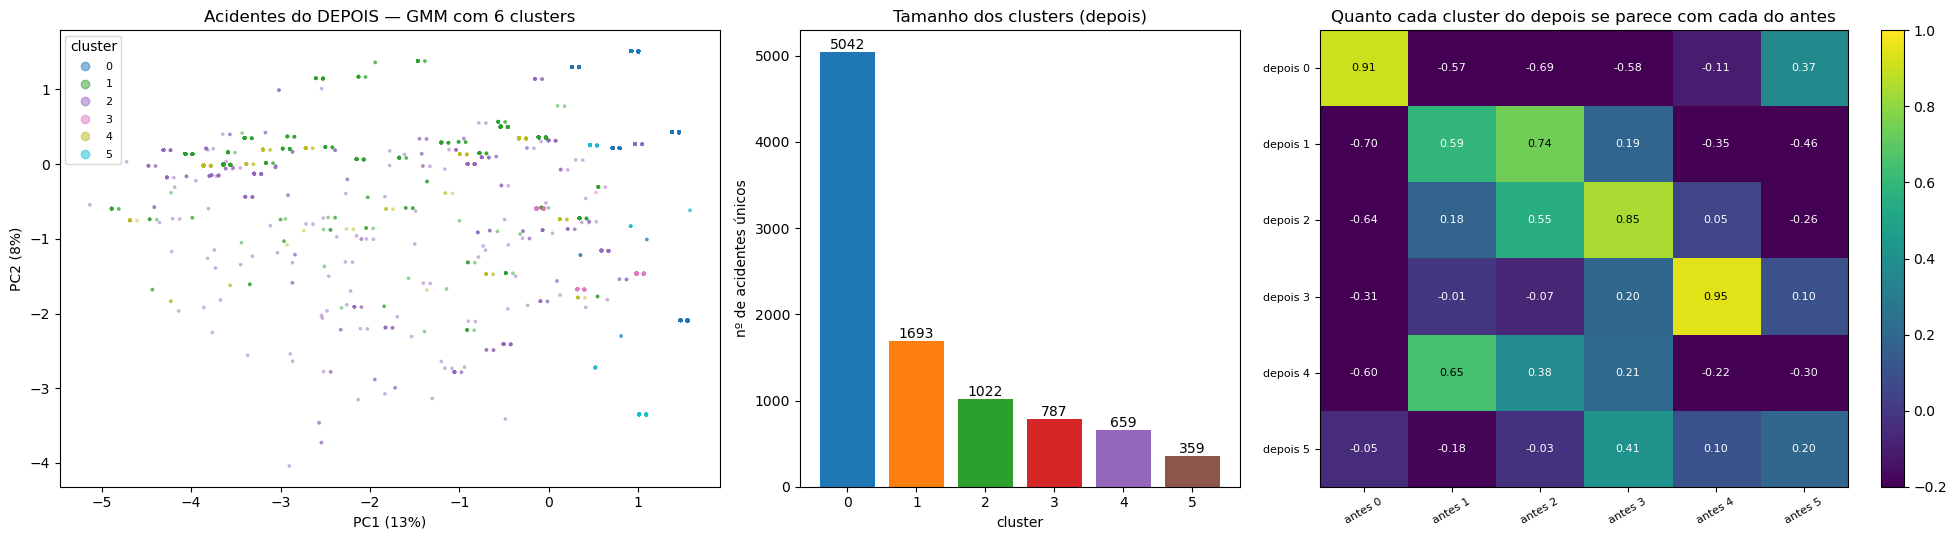

In [ ]:
# ---------------- PARÂMETROS DO "DEPOIS" ----------------
K_GMM_DEPOIS = 6               # None = escolhe pelo BIC entre K_MIN e K_MAX (use o mesmo k do "antes" se quiser comparar cluster a cluster)

# ---------------- SÓ O PERÍODO "DEPOIS" ----------------
depois = (aci["periodo"] == "depois").to_numpy()
unico_d = ~pd.DataFrame({"c": chave, "p": aci["periodo"]}).duplicated().to_numpy()   # único dentro do próprio período
fit_d = depois & unico_d
print(f"Acidentes no 'depois': {depois.sum()} registros ({fit_d.sum()} acidentes únicos) em {aci.loc[depois, 'codigo_semaforo'].nunique()} semáforos")

# mesmo pré-processamento do "antes", mas ajustado só com os acidentes do "depois"
scaler_d = StandardScaler().fit(Xdf[fit_d]) if ESCALAR else None
base_d = scaler_d.transform(Xdf) if ESCALAR else Xdf.to_numpy()
pca_d = PCA(n_components=VARIANCIA_PCA, random_state=SEMENTE).fit(base_d[fit_d])
Z_d = pca_d.transform(base_d)
print(f"{Xdf.shape[1]} atributos -> {Z_d.shape[1]} componentes ({VARIANCIA_PCA:.0%} da variância)")

if K_GMM_DEPOIS is None:
    bic = {k: GaussianMixture(k, covariance_type=COVARIANCIA_GMM, n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                              random_state=SEMENTE).fit(Z_d[fit_d]).bic(Z_d[fit_d]) for k in range(K_MIN, K_MAX + 1)}
    K_GMM_DEPOIS = min(bic, key=bic.get)
    print("BIC por k:", {k: round(v) for k, v in bic.items()}, "-> k =", K_GMM_DEPOIS)

# ---------------- GMM DO "DEPOIS" ----------------
gm_depois = GaussianMixture(K_GMM_DEPOIS, covariance_type=COVARIANCIA_GMM, n_init=N_INIT, reg_covar=REG_COVAR_GMM,
                            random_state=SEMENTE).fit(Z_d[fit_d])
ordem_depois = np.argsort(-gm_depois.predict_proba(Z_d[fit_d]).sum(0))        # cluster 0 = o mais frequente no "depois"
P_depois = gm_depois.predict_proba(Z_d[depois])[:, ordem_depois]
aci.loc[depois, "cluster_depois"] = P_depois.argmax(1)
aci.loc[depois, "certeza_depois"] = P_depois.max(1)

# ---------------- RESULTADOS ----------------
tam_d = aci.loc[depois & unico_d, "cluster_depois"].value_counts().sort_index()
print(f"\nCerteza média da atribuição: {aci.loc[depois, 'certeza_depois'].mean():.2f} | acidentes com certeza < 0,9: {(aci.loc[depois, 'certeza_depois'] < 0.9).mean():.1%}")
geral_d = Xdf[fit_d].mean()
print("\n=== Clusters do DEPOIS — perfil (atributo: % no cluster | % geral do depois) ===")
for c in range(K_GMM_DEPOIS):
    sel = fit_d & (aci["cluster_depois"] == c).to_numpy()
    pc = Xdf[sel].mean()
    top = (pc - geral_d).sort_values(ascending=False).head(5).index
    print(f"cluster {c} (n={tam_d.get(c, 0)}, {tam_d.get(c, 0) / tam_d.sum():.0%}): " + "; ".join(f"{a} {pc[a]:.0%}|{geral_d[a]:.0%}" for a in top))

comp_depois = pd.crosstab(aci.loc[depois, "codigo_semaforo"], aci.loc[depois, "cluster_depois"].astype(int), normalize="index")
print(f"\nComposição por semáforo calculada para {len(comp_depois)} semáforos (variável comp_depois)")

# ---------------- CORRESPONDÊNCIA: cada cluster do "depois" se parece com qual cluster do "antes"? ----------------
# como os dois GMMs foram ajustados separadamente, "cluster 2 do antes" e "cluster 2 do depois" NÃO são o mesmo grupo;
# a similaridade (cosseno) compara o perfil de atributos de cada cluster, em desvio em relação à média do próprio período
perfil_a = Xdf[fit].groupby(aci.loc[fit, "cluster_antes"].astype(int)).mean() - Xdf[fit].mean()
perfil_d = Xdf[fit_d].groupby(aci.loc[fit_d, "cluster_depois"].astype(int)).mean() - geral_d
A, D = perfil_a.to_numpy(), perfil_d.to_numpy()
sim = (D / np.linalg.norm(D, axis=1, keepdims=True)) @ (A / np.linalg.norm(A, axis=1, keepdims=True)).T
sim = pd.DataFrame(sim, index=[f"depois {c}" for c in perfil_d.index], columns=[f"antes {c}" for c in perfil_a.index])
print("\n=== Similaridade entre clusters do depois (linhas) e do antes (colunas); 1 = perfis iguais ===")
display(sim.round(2))
print("Cluster do antes mais parecido com cada cluster do depois:")
for c, (melhor, valor) in enumerate(zip(sim.idxmax(axis=1), sim.max(axis=1))):
    print(f"  depois {c} ≈ {melhor} (similaridade {valor:.2f})")

fig, eixos = plt.subplots(1, 3, figsize=(20, 5.5), gridspec_kw={"width_ratios": [3, 2, 3]})
idx = rng.choice(np.where(fit_d)[0], size=min(AMOSTRA_PLOT, fit_d.sum()), replace=False)
pts = eixos[0].scatter(Z_d[idx, 0], Z_d[idx, 1], c=aci.loc[idx, "cluster_depois"], cmap="tab10", s=7, alpha=0.5, edgecolor="none")
eixos[0].set_xlabel(f"PC1 ({pca_d.explained_variance_ratio_[0]:.0%})"); eixos[0].set_ylabel(f"PC2 ({pca_d.explained_variance_ratio_[1]:.0%})")
eixos[0].set_title(f"Acidentes do DEPOIS — GMM com {K_GMM_DEPOIS} clusters")
eixos[0].legend(*pts.legend_elements(), title="cluster", fontsize=8)
barras = eixos[1].bar(tam_d.index, tam_d.values, color=plt.get_cmap("tab10")(tam_d.index.astype(int) % 10))
eixos[1].bar_label(barras); eixos[1].set_xlabel("cluster"); eixos[1].set_ylabel("nº de acidentes únicos")
eixos[1].set_title("Tamanho dos clusters (depois)")
im = eixos[2].imshow(sim.to_numpy(), cmap="viridis", vmin=-0.2, vmax=1, aspect="auto")
for i in range(sim.shape[0]):
    for j in range(sim.shape[1]):
        eixos[2].text(j, i, f"{sim.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="w" if sim.iloc[i, j] < 0.6 else "k")
eixos[2].set_xticks(range(sim.shape[1])); eixos[2].set_xticklabels(sim.columns, rotation=30, fontsize=8)
eixos[2].set_yticks(range(sim.shape[0])); eixos[2].set_yticklabels(sim.index, fontsize=8)
eixos[2].set_title("Quanto cada cluster do depois se parece com cada do antes")
plt.colorbar(im, ax=eixos[2])
plt.tight_layout(); plt.show()

# anotações:
# Em média, cada semáforo tem 3,9 anos de dados no antes e 6,1 no depois.